# 🌲 Notebook 03 — Random Forest Multi-Horizon
**Model:** Random Forest dengan RandomizedSearchCV + TimeSeriesSplit

Horizon: **60 menit**, **180 menit**, **360 menit** ke depan


In [1]:
# ── CELL 1: Import Library ─────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json, os, warnings, joblib
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import randint, uniform

plt.style.use('seaborn-v0_8-whitegrid')
os.makedirs('models',  exist_ok=True)
os.makedirs('dataset', exist_ok=True)

HORIZONS = ['60m', '180m', '360m']
TARGET_MAP = {'60m': 'target_60m', '180m': 'target_180m', '360m': 'target_360m'}

print('[OK] Library berhasil diimport')
print(f'  scikit-learn : {__import__("sklearn").__version__}')


[OK] Library berhasil diimport
  scikit-learn : 1.9.0


In [2]:
# ── CELL 2: Fungsi Evaluasi ─────────────────────────────────────
def evaluasi(y_true, y_pred, label=''):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / (np.abs(y_true) + 1e-8))) * 100
    if label:
        print(f'  [{label}] MAE={mae:.4f}  RMSE={rmse:.4f}  R²={r2:.4f}  MAPE={mape:.2f}%')
    return {'MAE': float(mae), 'RMSE': float(rmse), 'R2': float(r2), 'MAPE': float(mape)}

print('[OK] Fungsi evaluasi siap')


[OK] Fungsi evaluasi siap


In [3]:
# ── CELL 3: Hyperparameter Search Space ────────────────────────
param_dist = {
    'n_estimators'    : randint(80, 201),     # 80–200 pohon
    'max_depth'       : randint(8, 18),        # 8–17 kedalaman
    'min_samples_leaf': randint(5, 21),        # mencegah overfitting
    'max_features'    : ['sqrt', 'log2', 0.5],
    'min_samples_split': randint(5, 20),
}
N_ITER = 20   # iterasi RandomizedSearch
N_CV   = 3    # fold TimeSeriesSplit (cepat)

print('=== 🔧 Hyperparameter Search Space ===')
print(f'  n_estimators    : 80 – 200')
print(f'  max_depth       : 8  – 17')
print(f'  min_samples_leaf: 5  – 20')
print(f'  max_features    : sqrt / log2 / 0.5')
print(f'  Iterasi RandomizedSearch : {N_ITER}')
print(f'  TimeSeriesSplit  folds   : {N_CV}')


=== 🔧 Hyperparameter Search Space ===
  n_estimators    : 80 – 200
  max_depth       : 8  – 17
  min_samples_leaf: 5  – 20
  max_features    : sqrt / log2 / 0.5
  Iterasi RandomizedSearch : 20
  TimeSeriesSplit  folds   : 3


In [4]:
# ── CELL 4: Training RF per Horizon ─────────────────────────────
rf_results = {}

for horizon in HORIZONS:
    print(f'\n{"="*55}')
    print(f'  🌲 Random Forest — Horizon {horizon}')
    print(f'{"="*55}')

    target = TARGET_MAP[horizon]

    # Load data
    df_train = pd.read_csv(f'dataset/data_train_{horizon}.csv',
                            parse_dates=['waktu_pembacaan'])
    df_test  = pd.read_csv(f'dataset/data_test_{horizon}.csv',
                            parse_dates=['waktu_pembacaan'])
    with open(f'models/feature_cols_{horizon}.json') as f:
        feat_cols = json.load(f)

    X_train = df_train[feat_cols].values
    y_train = df_train[target].values
    X_test  = df_test[feat_cols].values
    y_test  = df_test[target].values

    print(f'  Data: train={len(X_train):,} | test={len(X_test):,} | fitur={len(feat_cols)}')

    # RandomizedSearchCV dengan TimeSeriesSplit
    tscv = TimeSeriesSplit(n_splits=N_CV)
    base_rf = RandomForestRegressor(n_jobs=-1, random_state=42, oob_score=False)

    search = RandomizedSearchCV(
        estimator  = base_rf,
        param_distributions = param_dist,
        n_iter     = N_ITER,
        cv         = tscv,
        scoring    = 'neg_root_mean_squared_error',
        n_jobs     = -1,
        random_state = 42,
        verbose    = 0
    )
    print('  Mencari hyperparameter terbaik...')
    search.fit(X_train, y_train)

    best_params = search.best_params_
    best_cv_rmse = -search.best_score_
    print(f'  Best CV-RMSE : {best_cv_rmse:.4f}')
    print(f'  Best params  : {best_params}')

    # Train final model dengan best params
    rf_final = RandomForestRegressor(
        **best_params,
        n_jobs=-1,
        random_state=42,
        oob_score=True
    )
    rf_final.fit(X_train, y_train)
    print(f'  OOB Score    : {rf_final.oob_score_:.4f}')

    # Evaluasi
    y_pred_train = rf_final.predict(X_train)
    y_pred_test  = rf_final.predict(X_test)

    m_train = evaluasi(y_train, y_pred_train, f'Train-{horizon}')
    m_test  = evaluasi(y_test,  y_pred_test,  f'Test-{horizon}')

    # Simpan model dengan joblib
    model_path = f'models/rf_model_{horizon}.pkl'
    joblib.dump(rf_final, model_path, compress=3)
    size_mb = os.path.getsize(model_path) / 1e6
    print(f'  [OK] Model disimpan: {model_path} ({size_mb:.1f} MB)')

    # Simpan prediksi test
    df_pred = df_test[['waktu_pembacaan', target]].copy()
    df_pred['prediksi_rf'] = y_pred_test
    df_pred['residual_rf'] = y_test - y_pred_test
    df_pred.to_csv(f'dataset/prediksi_rf_{horizon}.csv', index=False)

    rf_results[horizon] = {
        'best_params' : best_params,
        'cv_rmse'     : float(best_cv_rmse),
        'oob_score'   : float(rf_final.oob_score_),
        'train_metrics': m_train,
        'test_metrics' : m_test,
        'model_size_mb': float(size_mb),
        'n_features'   : len(feat_cols),
    }

# Simpan ringkasan metrik
with open('models/rf_metrics_all.json', 'w') as f:
    json.dump(rf_results, f, indent=2)

print('\n[OK] Semua model RF selesai dilatih!')



  🌲 Random Forest — Horizon 60m
  Data: train=94,455 | test=23,614 | fitur=83
  Mencari hyperparameter terbaik...
  Best CV-RMSE : 8.9707
  Best params  : {'max_depth': 11, 'max_features': 'log2', 'min_samples_leaf': 12, 'min_samples_split': 8, 'n_estimators': 81}
  OOB Score    : 0.9810
  [Train-60m] MAE=1.0118  RMSE=2.3072  R²=0.9836  MAPE=1.91%
  [Test-60m] MAE=1.7420  RMSE=2.7802  R²=0.9795  MAPE=3.06%
  [OK] Model disimpan: models/rf_model_60m.pkl (3.7 MB)

  🌲 Random Forest — Horizon 180m
  Data: train=94,359 | test=23,590 | fitur=83
  Mencari hyperparameter terbaik...
  Best CV-RMSE : 11.3377
  Best params  : {'max_depth': 11, 'max_features': 'log2', 'min_samples_leaf': 19, 'min_samples_split': 19, 'n_estimators': 151}
  OOB Score    : 0.9774
  [Train-180m] MAE=1.2264  RMSE=2.5572  R²=0.9799  MAPE=2.32%
  [Test-180m] MAE=2.7958  RMSE=4.1895  R²=0.9535  MAPE=4.57%
  [OK] Model disimpan: models/rf_model_180m.pkl (5.7 MB)

  🌲 Random Forest — Horizon 360m
  Data: train=94,215 | te

=== Ringkasan Performa Random Forest (Test Set) ===
Horizon       MAE     RMSE       R2   MAPE(%)
---------------------------------------------
60m        1.7420   2.7802   0.9795      3.06
180m       2.7958   4.1895   0.9535      4.57
360m       4.1376   6.2605   0.8959      6.57



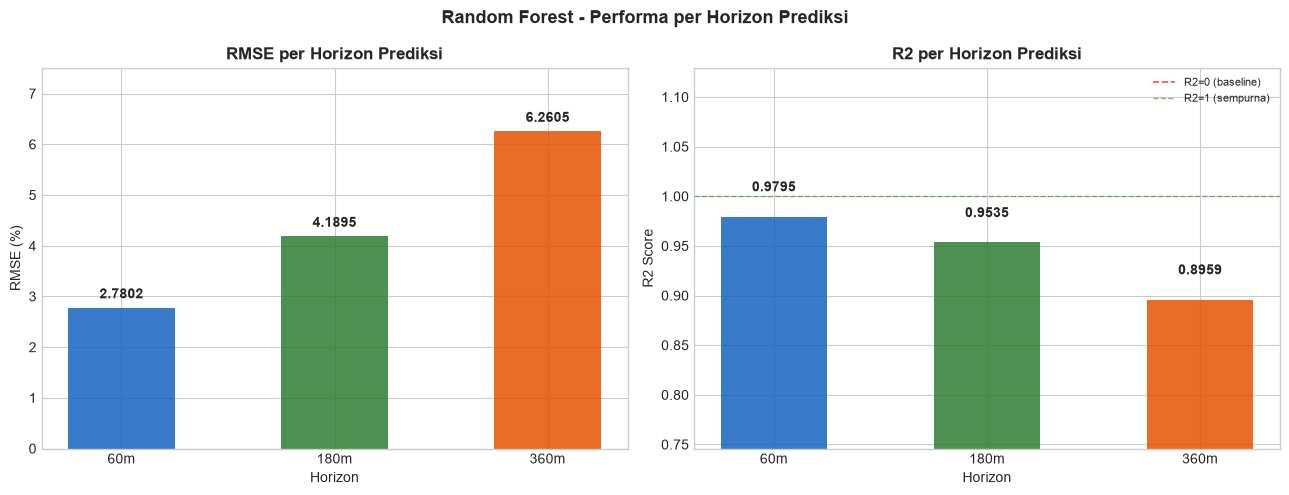

[OK] Plot RF multi-horizon disimpan


In [5]:
# ── CELL 5: Ringkasan Metrik RF ────────────────────────────────
print('=== Ringkasan Performa Random Forest (Test Set) ===')
print(f'{"Horizon":<8} {"MAE":>8} {"RMSE":>8} {"R2":>8} {"MAPE(%)":>9}')
print('-' * 45)
for h, res in rf_results.items():
    mt = res['test_metrics']
    r2_str = f'{mt["R2"]:>8.4f}' if mt["R2"] >= 0 else f'{mt["R2"]:>8.4f} (!)'
    print(f'{h:<8} {mt["MAE"]:>8.4f} {mt["RMSE"]:>8.4f} {r2_str} {mt["MAPE"]:>9.2f}')

print()
if any(rf_results[h]['test_metrics']['R2'] < 0 for h in rf_results):
    print('[PERHATIAN] R2 negatif artinya model lebih buruk dari rata-rata.')
    print('            Coba tambah fitur lag lebih panjang atau perbesar N_ITER.')

# ── Plot RMSE & R2 per horizon ───────────────────────────────
horizons_list = list(rf_results.keys())
rmse_vals = [rf_results[h]['test_metrics']['RMSE'] for h in horizons_list]
r2_vals   = [rf_results[h]['test_metrics']['R2']   for h in horizons_list]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Random Forest - Performa per Horizon Prediksi', fontsize=13, fontweight='bold')

colors_h = ['#1565C0', '#2E7D32', '#E65100']

# ── Subplot 1: RMSE ──────────────────────────────────────────
bars = axes[0].bar(horizons_list, rmse_vals, color=colors_h, alpha=0.85, width=0.5)
axes[0].set_title('RMSE per Horizon Prediksi', fontweight='bold')
axes[0].set_xlabel('Horizon')
axes[0].set_ylabel('RMSE (%)')
axes[0].set_ylim(0, max(rmse_vals) * 1.20)
for bar, v in zip(bars, rmse_vals):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        v + max(rmse_vals) * 0.02,
        f'{v:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10
    )

# ── Subplot 2: R2 (dynamic ylim, handles negative) ───────────
bars2 = axes[1].bar(horizons_list, r2_vals, color=colors_h, alpha=0.85, width=0.5)
axes[1].set_title('R2 per Horizon Prediksi', fontweight='bold')
axes[1].set_xlabel('Horizon')
axes[1].set_ylabel('R2 Score')

# Dynamic ylim: aman untuk R2 positif maupun negatif
r2_min = min(r2_vals)
r2_max = max(r2_vals)
padding = max(abs(r2_max - r2_min) * 0.20, 0.15)
axes[1].set_ylim(r2_min - padding, r2_max + padding)

# Garis referensi R2=0 dan R2=1
axes[1].axhline(y=0, color='red',    linestyle='--', linewidth=1.2,
                alpha=0.7, label='R2=0 (baseline)')
axes[1].axhline(y=1, color='green',  linestyle='--', linewidth=1.0,
                alpha=0.5, label='R2=1 (sempurna)')
axes[1].legend(fontsize=8)

# Label di atas bar (positif) atau di bawah bar (negatif)
for bar, v in zip(bars2, r2_vals):
    x_pos = bar.get_x() + bar.get_width() / 2
    if v >= 0:
        y_pos  = v + padding * 0.15
        valign = 'bottom'
    else:
        y_pos  = v - padding * 0.15
        valign = 'top'
    axes[1].text(x_pos, y_pos, f'{v:.4f}',
                 ha='center', va=valign, fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('dataset/plot_rf_multihorizon.png', dpi=150, bbox_inches='tight')
plt.show()
print('[OK] Plot RF multi-horizon disimpan')


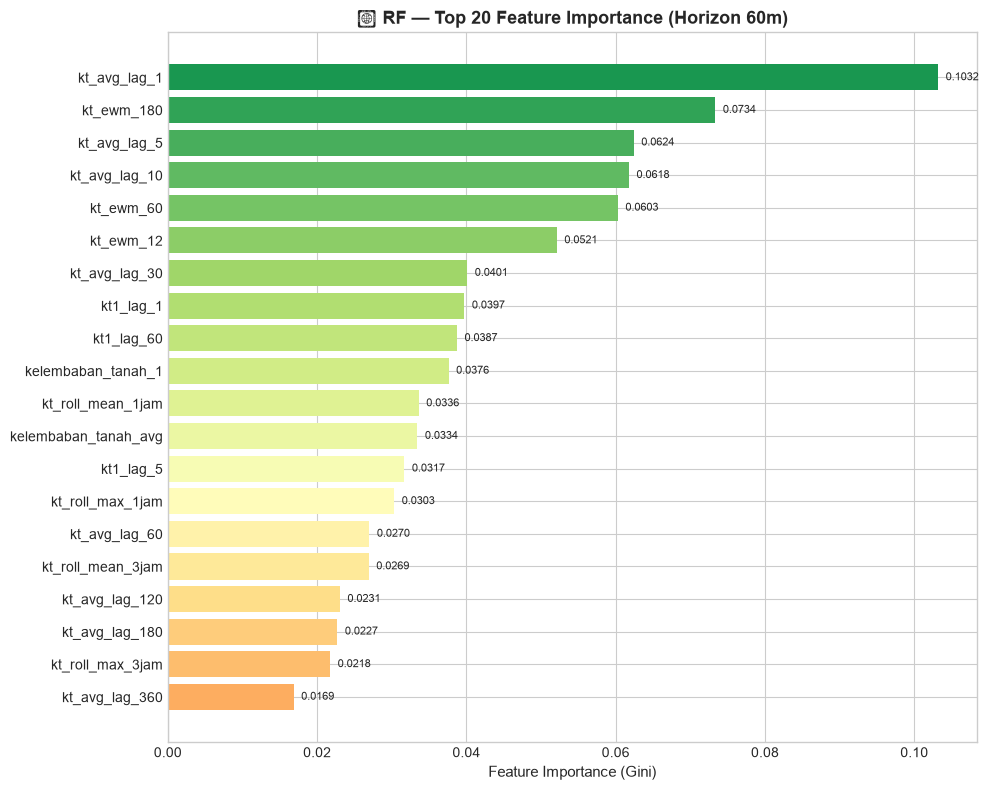


=== Top 10 Fitur Terpenting (Horizon 60m) ===
kt_avg_lag_1          0.103204
kt_ewm_180            0.073355
kt_avg_lag_5          0.062425
kt_avg_lag_10         0.061783
kt_ewm_60             0.060299
kt_ewm_12             0.052119
kt_avg_lag_30         0.040119
kt1_lag_1             0.039731
kt1_lag_60            0.038740
kelembaban_tanah_1    0.037621


In [6]:
# ── CELL 6: Feature Importance (Horizon 60m) ───────────────────
horizon_fi = '60m'
rf_fi = joblib.load(f'models/rf_model_{horizon_fi}.pkl')
with open(f'models/feature_cols_{horizon_fi}.json') as f:
    feat_cols_fi = json.load(f)

importances = pd.Series(rf_fi.feature_importances_, index=feat_cols_fi)
importances = importances.sort_values(ascending=False)
top_n = 20

fig, ax = plt.subplots(figsize=(10, 8))
colors_fi = plt.cm.RdYlGn(np.linspace(0.3, 0.9, top_n))
bars = ax.barh(importances.head(top_n).index[::-1],
               importances.head(top_n).values[::-1],
               color=colors_fi)
ax.set_xlabel('Feature Importance (Gini)', fontsize=11)
ax.set_title(f'🌲 RF — Top {top_n} Feature Importance (Horizon {horizon_fi})',
             fontsize=13, fontweight='bold')
for bar, val in zip(bars, importances.head(top_n).values[::-1]):
    ax.text(val+0.001, bar.get_y()+bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=8)
plt.tight_layout()
plt.savefig('dataset/plot_rf_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'\n=== Top 10 Fitur Terpenting (Horizon {horizon_fi}) ===')
print(importances.head(10).to_string())


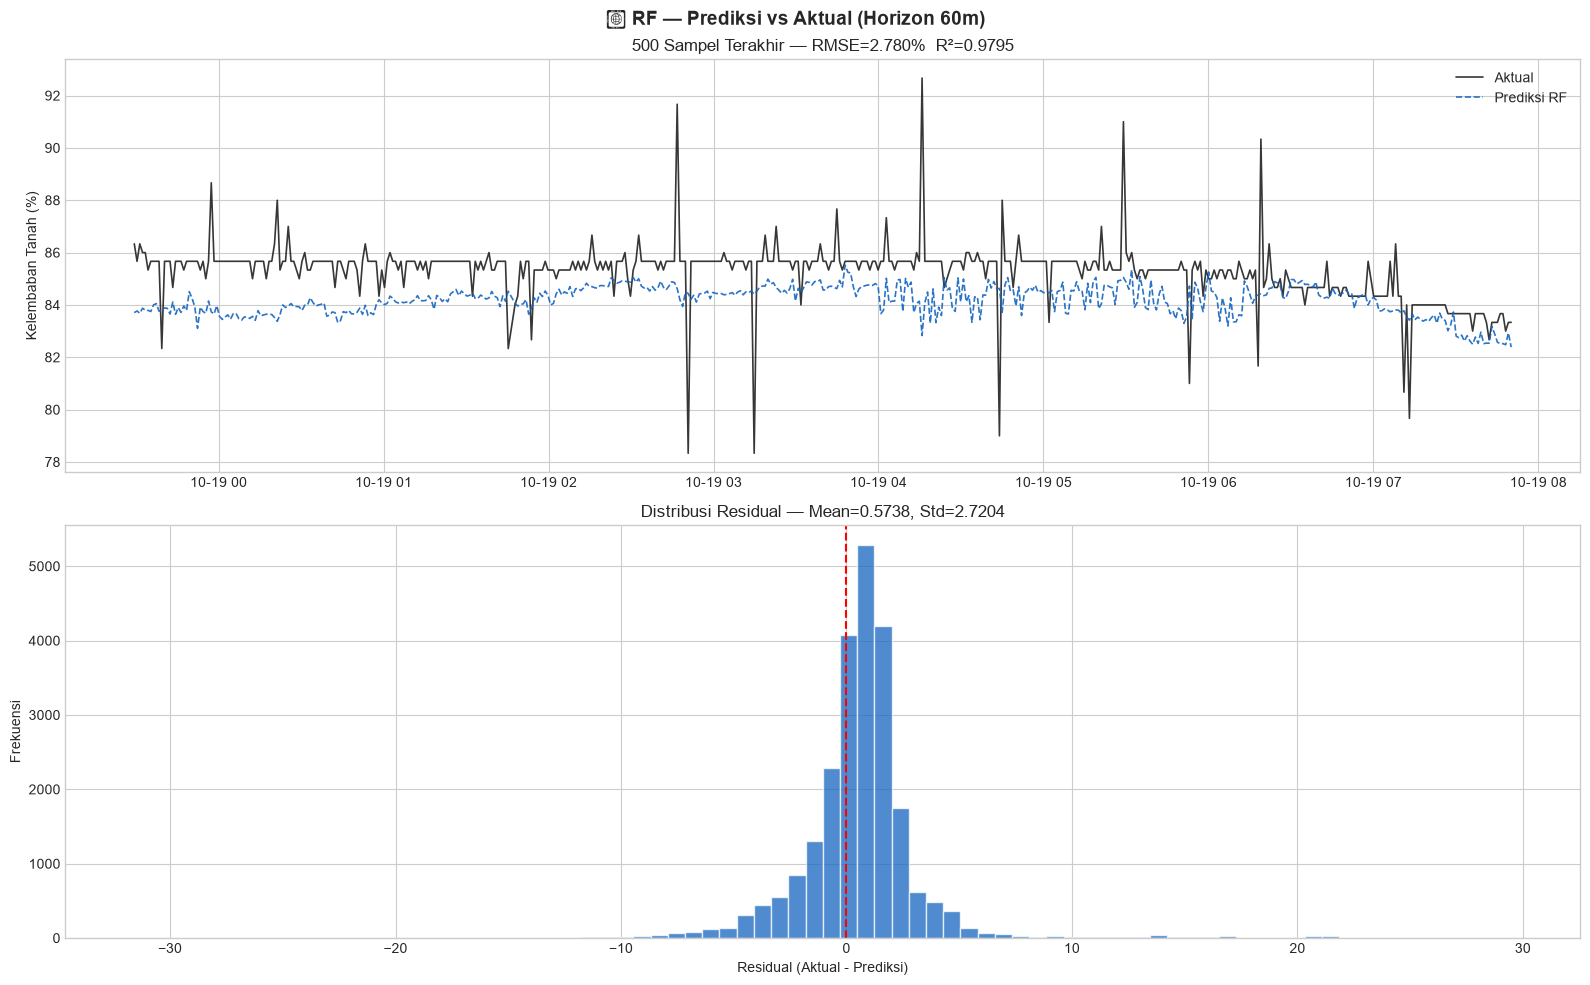

[OK] Selesai! Lanjut ke → 04_xgboost.ipynb


In [7]:
# ── CELL 7: Visualisasi Prediksi vs Aktual (Horizon 60m) ───────
horizon_viz = '60m'
target_viz  = TARGET_MAP[horizon_viz]

df_viz  = pd.read_csv(f'dataset/prediksi_rf_{horizon_viz}.csv',
                       parse_dates=['waktu_pembacaan'])
n_plot  = 500
df_p    = df_viz.tail(n_plot)

fig, axes = plt.subplots(2, 1, figsize=(16, 10))
fig.suptitle(f'🌲 RF — Prediksi vs Aktual (Horizon {horizon_viz})',
             fontsize=14, fontweight='bold')

axes[0].plot(df_p['waktu_pembacaan'], df_p[target_viz],
             color='#212121', linewidth=1.2, label='Aktual', alpha=0.9)
axes[0].plot(df_p['waktu_pembacaan'], df_p['prediksi_rf'],
             color='#1565C0', linewidth=1.2, linestyle='--',
             label='Prediksi RF', alpha=0.9)
axes[0].set_ylabel('Kelembaban Tanah (%)')
axes[0].set_title(f'{n_plot} Sampel Terakhir — RMSE={rf_results[horizon_viz]["test_metrics"]["RMSE"]:.3f}%  R²={rf_results[horizon_viz]["test_metrics"]["R2"]:.4f}')
axes[0].legend()

residuals = df_viz['residual_rf'].values
axes[1].hist(residuals, bins=80, color='#1565C0', alpha=0.75, edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Residual (Aktual - Prediksi)')
axes[1].set_ylabel('Frekuensi')
axes[1].set_title(f'Distribusi Residual — Mean={residuals.mean():.4f}, Std={residuals.std():.4f}')

plt.tight_layout()
plt.savefig('dataset/plot_rf_prediksi.png', dpi=150, bbox_inches='tight')
plt.show()
print('[OK] Selesai! Lanjut ke → 04_xgboost.ipynb')
